<a href="https://colab.research.google.com/github/jhafssae-2510/FDM5-travaux-/blob/main/notebooks/03_numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aelkharrim/FDM5-3P/blob/main/notebooks/03_numpy.ipynb)

# Python pour la physique — 3. NumPy : créer et manipuler des données numériques

> 💡 **Astuce**
>
> **Rappel** : exécutez les cellules dans l'ordre avec **Maj + Entrée**. Les solutions des exercices sont masquées dans des cellules « Solution » : essayez d'abord par vous-même !

In [10]:
# Cellule de préparation (facultative) : exécutez-la une fois au début.
# Sur Google Colab, NumPy, SciPy, Matplotlib et SymPy sont déjà installés.
import sys
EN_COLAB = 'google.colab' in sys.modules
print('Exécution dans Google Colab' if EN_COLAB else 'Exécution en local')

Exécution dans Google Colab


# L'objet tableau NumPy

In [2]:
# Notre import habituel.
import numpy as np

## Que sont NumPy et les tableaux NumPy ?

**NumPy** fournit :

- un paquet d'extension de Python pour les tableaux multidimensionnels ;
- une implémentation proche du matériel (efficacité) ;
- un paquet conçu pour le calcul scientifique (commodité) ;
- une implémentation du *calcul orienté tableaux*.

In [3]:
import numpy as np

a = np.array([0, 1, 2, 3])
a

array([0, 1, 2, 3])

Par exemple, un tableau peut contenir :

- les valeurs d'une expérience ou d'une simulation à des pas de temps discrets ;
- un signal enregistré par un appareil de mesure, par exemple une onde sonore ;
- les pixels d'une image, en niveaux de gris ou en couleur ;
- des données 3D mesurées à différentes positions X-Y-Z, par exemple une IRM ;
- …

**Pourquoi c'est utile :** un conteneur économe en mémoire, qui fournit des opérations numériques rapides.

In [5]:
L = range(1000)
%timeit [i**2 for i in L]

84.4 µs ± 25.4 µs per loop (mean ± std. dev. of 7 runs, 10000 loops each)


In [6]:
a = np.arange(1000)
%timeit a**2

1.36 µs ± 329 ns per loop (mean ± std. dev. of 7 runs, 1000000 loops each)


La version NumPy est typiquement 10 à 100 fois plus rapide (regardez les temps affichés).

### Documentation de référence

**Sur le web** : <https://numpy.org/doc/>

**Aide interactive** : tapez `np.array?` dans une cellule, ou utilisez la commande `help` de Python :

In [7]:
help(np.array)

Help on built-in function array in module numpy:

array(
    object,
    dtype=None,
    *,
    copy=True,
    order='K',
    subok=False,
    ndmin=0,
    ndmax=0,
    like=None
)
    array(object, dtype=None, *, copy=True, order='K', subok=False, ndmin=0,
          ndmax=0, like=None)

    Create an array.

    Parameters
    ----------
    object : array_like
        An array, any object exposing the array interface, an object whose
        ``__array__`` method returns an array, or any (nested) sequence.
        If object is a scalar, a 0-dimensional array containing object is
        returned.
    dtype : data-type, optional
        The desired data-type for the array. If not given, NumPy will try to use
        a default ``dtype`` that can represent the values (by applying promotion
        rules when necessary.)
    copy : bool, optional
        If ``True`` (default), then the array data is copied. If ``None``,
        a copy will only be made if ``__array__`` returns a copy, if 

### Convention d'importation

La convention recommandée pour importer NumPy est :

In [8]:
import numpy as np

## Créer des tableaux

### Construction manuelle

- **1D** :

In [9]:
a = np.array([0, 1, 2, 3])
a

array([0, 1, 2, 3])

In [11]:
a.ndim

1

In [12]:
a.shape

(4,)

In [13]:
len(a)

4

- **2D, 3D, …** :

In [14]:
b = np.array([[0, 1, 2], [3, 4, 5]])    # tableau 2 x 3
b

array([[0, 1, 2],
       [3, 4, 5]])

In [15]:
b.ndim

2

In [16]:
b.shape

(2, 3)

In [17]:
len(b)     # renvoie la taille de la première dimension

2

In [18]:
c = np.array([[[1], [2]], [[3], [4]]])
c

array([[[1],
        [2]],

       [[3],
        [4]]])

In [19]:
c.shape

(2, 2, 1)

> **Exercice**
>
> - Créez un tableau simple à deux dimensions. Refaites d'abord les exemples ci-dessus, puis créez le vôtre : par exemple, les nombres impairs en ordre décroissant sur la première ligne, et les nombres pairs sur la seconde.
> - Utilisez les fonctions `len` et `np.shape` sur ces tableaux. Quel lien y a-t-il entre elles ? Et avec l'attribut `ndim` ?

In [20]:
import numpy as np

b = np.array([[7, 5, 3, 1],
              [2, 4, 6, 8]])
print(b)

[[7 5 3 1]
 [2 4 6 8]]


### Fonctions de création de tableaux

En pratique, on saisit rarement les éléments un par un…

**Régulièrement espacés** :

In [21]:
a = np.arange(10) # 0 .. n-1  (!)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [22]:
b = np.arange(1, 9, 2) # début, fin (exclue), pas
b

array([1, 3, 5, 7])

ou **par nombre de points** :

In [23]:
c = np.linspace(0, 1, 6)   # début, fin, nombre de points
c

array([0. , 0.2, 0.4, 0.6, 0.8, 1. ])

In [24]:
d = np.linspace(0, 1, 5, endpoint=False)
d

array([0. , 0.2, 0.4, 0.6, 0.8])

> 💡 **Astuce**
>
> En physique, `np.linspace` est l'outil de base pour créer un **axe de temps** ou d'espace : `t = np.linspace(0, 10, 1001)` donne 1001 instants de 0 à 10 s.


**Tableaux usuels** :

In [25]:
a = np.ones((3, 3))  # rappel : (3, 3) est un tuple
a

array([[1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.]])

In [26]:
b = np.zeros((2, 2))
b

array([[0., 0.],
       [0., 0.]])

In [27]:
c = np.eye(3)
c

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [28]:
d = np.diag(np.array([1, 2, 3, 4]))
d

array([[1, 0, 0, 0],
       [0, 2, 0, 0],
       [0, 0, 3, 0],
       [0, 0, 0, 4]])

- `np.random` : nombres aléatoires (générateur Mersenne Twister) :

In [29]:
rng = np.random.default_rng(27446968)
a = rng.random(4)       # uniforme dans [0, 1]
a

array([0.64613018, 0.48984931, 0.50851229, 0.22563948])

In [30]:
b = rng.standard_normal(4)      # gaussienne
b

array([-0.38250769, -0.61536465,  0.98131732,  0.59353096])

> **Exercices**
>
> - Expérimentez avec `arange`, `linspace`, `ones`, `zeros`, `eye` et `diag`.
> - Créez différents types de tableaux de nombres aléatoires.
> - Essayez de fixer la graine (*seed*) avant de créer un tableau aléatoire.
> - Regardez la fonction `np.empty`. Que fait-elle ? Quand peut-elle être utile ?



> **Exercice**
>
> - Construisez un tableau contenant : 1 2 3 4 5
> - Construisez un tableau contenant : -5, -4, -3, -2, -1
> - Construisez : 2 4 6 8
> - Construisez 15 nombres équidistants dans l'intervalle [0, 10]

In [31]:
import numpy as np

print(np.arange(5))
print(np.arange(2, 9, 2))
print(np.linspace(0, 1, 5))
print(np.ones((2, 3)))
print(np.zeros((2, 3)))
print(np.eye(3))
print(np.diag([1, 2, 3]))

[0 1 2 3 4]
[2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]
[[1. 1. 1.]
 [1. 1. 1.]]
[[0. 0. 0.]
 [0. 0. 0.]]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[[1 0 0]
 [0 2 0]
 [0 0 3]]


In [32]:
np.random.seed(42)
print(np.random.rand(3))

np.random.seed(42)
print(np.random.rand(3))

np.random.seed(42)
print(np.random.randint(0, 10, 5))

np.random.seed(42)
print(np.random.randn(3))

[0.37454012 0.95071431 0.73199394]
[0.37454012 0.95071431 0.73199394]
[6 3 7 4 6]
[ 0.49671415 -0.1382643   0.64768854]


In [34]:
import numpy as np

print(np.arange(1, 6))
print(np.arange(-5, 0))
print(np.arange(2, 9, 2))
print(np.linspace(0, 10, 15))

[1 2 3 4 5]
[-5 -4 -3 -2 -1]
[2 4 6 8]
[ 0.          0.71428571  1.42857143  2.14285714  2.85714286  3.57142857
  4.28571429  5.          5.71428571  6.42857143  7.14285714  7.85714286
  8.57142857  9.28571429 10.        ]


In [35]:
#@title Solution { display-mode: "form" }
print(np.arange(1, 6))
print(np.arange(-5, 0))
print(np.arange(2, 10, 2))
print(np.linspace(0, 10, 15))

[1 2 3 4 5]
[-5 -4 -3 -2 -1]
[2 4 6 8]
[ 0.          0.71428571  1.42857143  2.14285714  2.85714286  3.57142857
  4.28571429  5.          5.71428571  6.42857143  7.14285714  7.85714286
  8.57142857  9.28571429 10.        ]


## Types de données de base

Vous avez peut-être remarqué que, parfois, les éléments d'un tableau s'affichent avec un point final (par exemple `2.` au lieu de `2`). Cela vient d'une différence de type de données (*dtype*) :

In [36]:
a = np.array([1, 2, 3])
a.dtype

dtype('int64')

In [37]:
b = np.array([1., 2., 3.])
b.dtype

dtype('float64')

Différents types de données permettent de stocker les données plus compactement en mémoire, mais la plupart du temps on travaille simplement avec des nombres flottants. Notez que, dans l'exemple ci-dessus, NumPy détecte automatiquement le type à partir des données saisies.

Vous pouvez aussi préciser explicitement le type voulu :

In [38]:
c = np.array([1, 2, 3], dtype=float)
c.dtype

dtype('float64')

Le type **par défaut** est le flottant :

In [39]:
a = np.ones((3, 3))
a.dtype

dtype('float64')

Il existe d'autres types :

**Booléens**

In [40]:
e = np.array([True, False, False, True])
e.dtype

dtype('bool')

**Chaînes de caractères**

In [41]:
f = np.array(['Bonjour', 'Hello', 'Hallo'])
f.dtype     # <--- chaînes de 7 lettres au maximum

dtype('<U7')

**Et bien d'autres** : `int32`, `int64`, `uint32`, `uint64`, `complex128`, …

## Visualisation de base

Maintenant que nous avons nos premiers tableaux, visualisons-les. *Matplotlib* est une bibliothèque de tracé 2D. Dans Colab, les graphiques s'affichent directement sous la cellule.

In [42]:
import matplotlib.pyplot as plt  # la façon propre d'importer

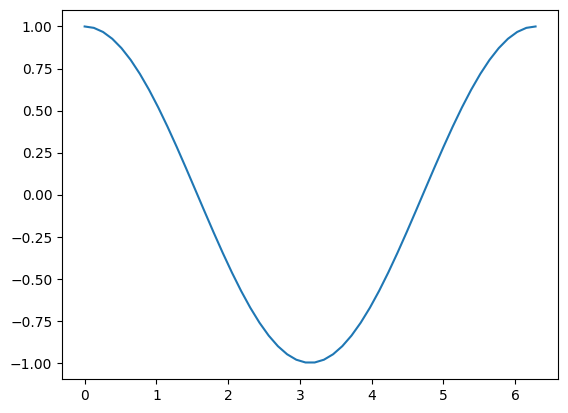

In [43]:
# Données d'exemple
x = np.linspace(0, 2 * np.pi)
y = np.cos(x)

plt.plot(x, y)       # tracé en ligne
plt.show()           # <-- affiche le graphique

- **Tracé 1D** :

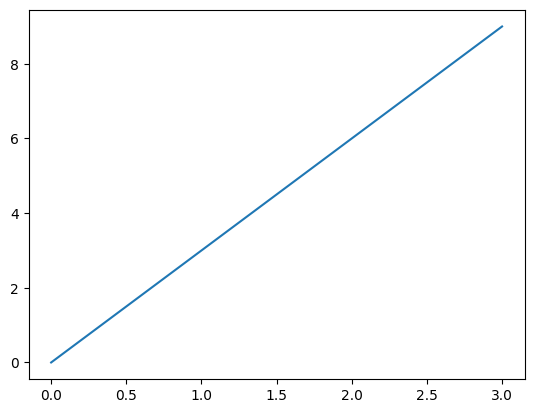

In [44]:
x = np.linspace(0, 3, 20)
y = np.linspace(0, 9, 20)
plt.plot(x, y)       # tracé en ligne
plt.show()

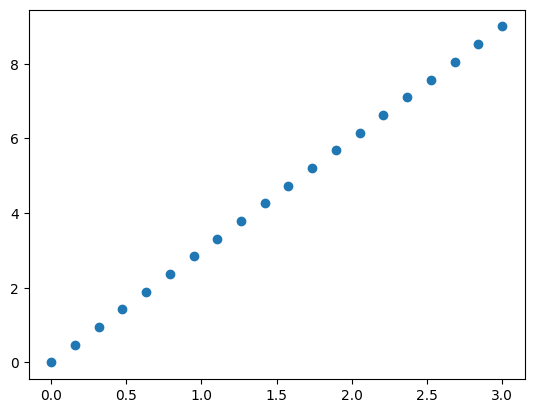

In [45]:
plt.plot(x, y, 'o')  # nuage de points
plt.show()

- **Tableaux 2D** (comme des images) :

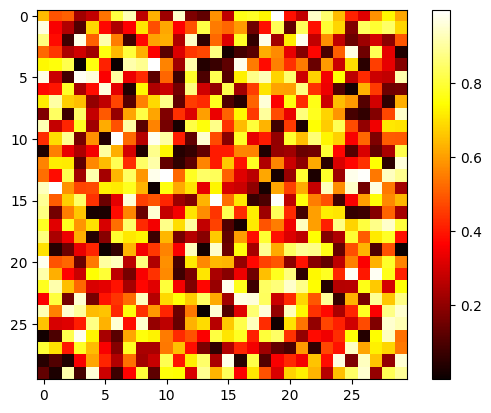

In [46]:
rng = np.random.default_rng(27446968)
image = rng.random((30, 30))
plt.imshow(image, cmap=plt.cm.hot)
plt.colorbar()
plt.show()

Nous détaillerons Matplotlib dans le carnet 4.


> **Exercice**
>
> - Tracez quelques tableaux simples : un cosinus en fonction du temps et une matrice 2D.
> - Essayez la table de couleurs `gray` sur la matrice 2D.

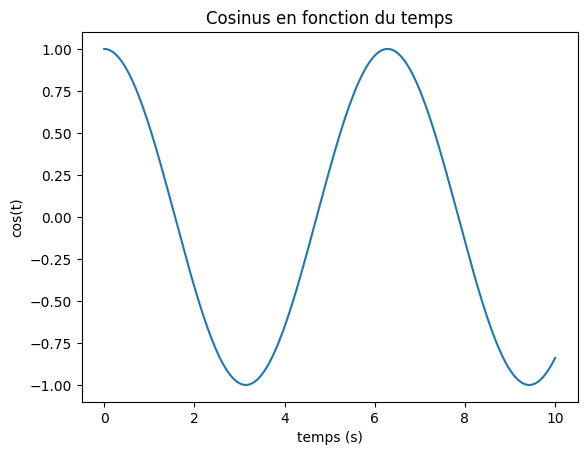

In [47]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 10, 200)
plt.plot(t, np.cos(t))
plt.title("Cosinus en fonction du temps")
plt.xlabel("temps (s)")
plt.ylabel("cos(t)")
plt.show()

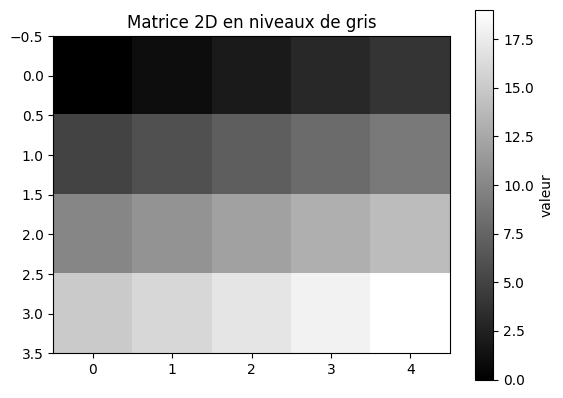

In [48]:
M = np.arange(20).reshape(4, 5)
plt.imshow(M, cmap="gray")
plt.colorbar(label="valeur")
plt.title("Matrice 2D en niveaux de gris")
plt.show()

### 📝 **Ma remarque**
J'ai tracé un cosinus avec `plt.plot` et une matrice 2D avec `plt.imshow`. Avec la table de couleurs `gray`, les petites valeurs sont en noir et les grandes en blanc.

## Indexation et découpage

On accède aux éléments d'un tableau, et on les modifie, comme pour les autres séquences Python (par exemple les listes) :

In [49]:
a = np.arange(10)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [50]:
a[0], a[2], a[-1]

(np.int64(0), np.int64(2), np.int64(9))

> ⚠️ **Attention**
>
> Les indices commencent à 0, comme pour les autres séquences Python (et le C/C++). En Fortran ou Matlab, ils commencent à 1.


L'idiome Python habituel pour inverser une séquence fonctionne :

In [51]:
a[::-1]

array([9, 8, 7, 6, 5, 4, 3, 2, 1, 0])

Pour les tableaux multidimensionnels, les indices sont des tuples d'entiers :

In [53]:
a = np.diag(np.arange(3))
a

array([[0, 0, 0],
       [0, 1, 0],
       [0, 0, 2]])

In [54]:
a[1, 1]

np.int64(1)

In [55]:
a[2, 1] = 10 # troisième ligne, deuxième colonne
a

array([[ 0,  0,  0],
       [ 0,  1,  0],
       [ 0, 10,  2]])

In [56]:
a[1]

array([0, 1, 0])

> 📝 **Note**
>
> - En 2D, la première dimension correspond aux **lignes**, la seconde aux **colonnes**.
> - Pour un tableau multidimensionnel `a`, `a[0]` signifie : tous les éléments des dimensions non précisées.


**Découpage** (*slicing*) : les tableaux, comme les autres séquences Python, peuvent être découpés :

In [57]:
a = np.arange(10)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [58]:
a[2:9:3] # [début:fin:pas]

array([2, 5, 8])

Notez que le dernier indice n'est pas inclus !

In [59]:
a[:4]

array([0, 1, 2, 3])

Les trois composantes ne sont pas toutes obligatoires : par défaut, `début` vaut 0, `fin` est le dernier élément et `pas` vaut 1 :

In [60]:
a[1:3]

array([1, 2])

In [61]:
a[::2]

array([0, 2, 4, 6, 8])

In [62]:
a[3:]

array([3, 4, 5, 6, 7, 8, 9])

Un petit résumé illustré de l'indexation et du découpage NumPy :

![Indexation NumPy](https://raw.githubusercontent.com/scipy-lectures/scipy-lecture-notes/master/pyximages/numpy_indexing.png)

On peut aussi combiner affectation et découpage :

In [63]:
a = np.arange(10)
a[5:] = 10
a

array([ 0,  1,  2,  3,  4, 10, 10, 10, 10, 10])

In [64]:
b = np.arange(5)
a[5:] = b[::-1]
a

array([0, 1, 2, 3, 4, 4, 3, 2, 1, 0])

> **Exercice**
>
> - Essayez les différentes variantes de découpage avec `début`, `fin` et `pas` : à partir d'un `linspace`, obtenez les nombres impairs en ordre décroissant et les nombres pairs en ordre croissant.
> - Reproduisez les découpages du schéma ci-dessus. Vous pouvez créer le tableau avec l'expression :
>
> ```python
> np.arange(6) + np.arange(0, 51, 10)[:, np.newaxis]
> ```

In [65]:
import numpy as np

a = np.linspace(0, 9, 10)
print(a)
print(a[::2])        # pairs en ordre croissant
print(a[::-1][::2])  # impairs en ordre décroissant

[0. 1. 2. 3. 4. 5. 6. 7. 8. 9.]
[0. 2. 4. 6. 8.]
[9. 7. 5. 3. 1.]


In [66]:
b = np.arange(6) + np.arange(0, 51, 10)[:, np.newaxis]
print(b)

[[ 0  1  2  3  4  5]
 [10 11 12 13 14 15]
 [20 21 22 23 24 25]
 [30 31 32 33 34 35]
 [40 41 42 43 44 45]
 [50 51 52 53 54 55]]


> **Exercice : création de tableaux**
>
>
> Créez les tableaux suivants (avec les bons types de données) :
>
> ```python
> [[1, 1, 1, 1],
>  [1, 1, 1, 1],
>  [1, 1, 1, 2],
>  [1, 6, 1, 1]]
>
> [[0., 0., 0., 0., 0.],
>  [2., 0., 0., 0., 0.],
>  [0., 3., 0., 0., 0.],
>  [0., 0., 4., 0., 0.],
>  [0., 0., 0., 5., 0.],
>  [0., 0., 0., 0., 6.]]
> ```
>
> *Objectif* : 3 instructions pour chacun.
>
> *Indice* : on accède aux éléments individuels comme dans une liste, par exemple `a[1]` ou `a[1, 2]`. Examinez aussi la docstring de `diag`.

In [67]:
import numpy as np

a = np.ones((4, 4), dtype=int)
a[2, 3] = 2
a[3, 1] = 6
print(a)

[[1 1 1 1]
 [1 1 1 1]
 [1 1 1 2]
 [1 6 1 1]]


In [68]:
d = np.diag([2., 3., 4., 5., 6.], k=-1)
b = d[:, :5]
print(b)

[[0. 0. 0. 0. 0.]
 [2. 0. 0. 0. 0.]
 [0. 3. 0. 0. 0.]
 [0. 0. 4. 0. 0.]
 [0. 0. 0. 5. 0.]
 [0. 0. 0. 0. 6.]]


In [69]:
#@title Solution { display-mode: "form" }
a = np.ones((4, 4), dtype=int)
a[3, 1] = 6
a[2, 3] = 2
print(a)

b = np.zeros((6, 5))
b[1:] = np.diag(np.arange(2, 7))
print(b)

[[1 1 1 1]
 [1 1 1 1]
 [1 1 1 2]
 [1 6 1 1]]
[[0. 0. 0. 0. 0.]
 [2. 0. 0. 0. 0.]
 [0. 3. 0. 0. 0.]
 [0. 0. 4. 0. 0.]
 [0. 0. 0. 5. 0.]
 [0. 0. 0. 0. 6.]]


> **Exercice : le pavage (*tiling*)**
>
>
> Parcourez la documentation de `np.tile` et utilisez cette fonction pour construire le tableau :
>
> ```python
> [[4, 3, 4, 3, 4, 3],
>  [2, 1, 2, 1, 2, 1],
>  [4, 3, 4, 3, 4, 3],
>  [2, 1, 2, 1, 2, 1]]
> ```

In [70]:
import numpy as np

bloc = np.array([[4, 3],
                 [2, 1]])
print(np.tile(bloc, (2, 3)))

[[4 3 4 3 4 3]
 [2 1 2 1 2 1]
 [4 3 4 3 4 3]
 [2 1 2 1 2 1]]


In [71]:
#@title Solution { display-mode: "form" }
bloc = np.array([[4, 3], [2, 1]])
a = np.tile(bloc, (2, 3))
a

array([[4, 3, 4, 3, 4, 3],
       [2, 1, 2, 1, 2, 1],
       [4, 3, 4, 3, 4, 3],
       [2, 1, 2, 1, 2, 1]])

## Copies et vues

Une opération de découpage crée une **vue** du tableau d'origine, c'est-à-dire simplement une autre façon d'accéder aux données. Le tableau d'origine n'est donc pas copié en mémoire. On peut utiliser `np.may_share_memory()` pour vérifier si deux tableaux partagent le même bloc mémoire (attention : cette fonction utilise des heuristiques et peut donner des faux positifs).

**Quand on modifie la vue, le tableau d'origine est modifié aussi** :

In [72]:
a = np.arange(10)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [73]:
b = a[::2]
b

array([0, 2, 4, 6, 8])

In [74]:
np.may_share_memory(a, b)

True

In [75]:
b[0] = 12
b

array([12,  2,  4,  6,  8])

In [76]:
a   # (!)

array([12,  1,  2,  3,  4,  5,  6,  7,  8,  9])

In [77]:
a = np.arange(10)
c = a[::2].copy()  # on force une copie
c[0] = 12
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [78]:
np.may_share_memory(a, c)

False

Ce comportement peut surprendre au début… mais il permet d'économiser à la fois de la mémoire et du temps.

### Exemple détaillé : le crible d'Ératosthène

Calculons les nombres premiers entre 0 et 99 avec un crible.

D'abord, construisons un tableau booléen `est_premier` de forme (100,), rempli de `True` :

In [80]:
est_premier = np.ones((100,), dtype=bool)

Ensuite, barrons 0 et 1, qui ne sont pas premiers :

In [81]:
est_premier[:2] = 0

Pour chaque entier `j` à partir de 2, barrons ses multiples supérieurs :

In [82]:
N_max = int(np.sqrt(len(est_premier) - 1))
for j in range(2, N_max + 1):
    est_premier[2*j::j] = False

Parcourez `help(np.nonzero)` et affichez les nombres premiers.

In [83]:
print(np.nonzero(est_premier)[0])

[ 2  3  5  7 11 13 17 19 23 29 31 37 41 43 47 53 59 61 67 71 73 79 83 89
 97]


In [84]:
#@title Solution { display-mode: "form" }
np.nonzero(est_premier)[0]

array([ 2,  3,  5,  7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59,
       61, 67, 71, 73, 79, 83, 89, 97])

## Indexation avancée (*fancy indexing*)

Les tableaux NumPy peuvent être indexés avec des découpages, mais aussi avec des tableaux de booléens ou d'entiers (**masques**). Cette méthode s'appelle *fancy indexing*. Elle crée des **copies, pas des vues**.

### Avec des masques booléens

In [85]:
rng = np.random.default_rng(27446968)
a = rng.integers(0, 21, 15)
a

array([ 3, 13, 12, 10, 10, 10, 18,  4,  8,  5,  6, 11, 12, 17,  3])

In [86]:
(a % 3 == 0)

array([ True, False,  True, False, False, False,  True, False, False,
       False,  True, False,  True, False,  True])

In [87]:
masque = (a % 3 == 0)
extrait_de_a = a[masque] # ou bien a[a%3==0]
extrait_de_a             # extrait un sous-tableau avec le masque

array([ 3, 12, 18,  6, 12,  3])

L'indexation par masque est très utile pour affecter une nouvelle valeur à un sous-tableau :

In [88]:
a[a % 3 == 0] = -1
a

array([-1, 13, -1, 10, 10, 10, -1,  4,  8,  5, -1, 11, -1, 17, -1])

En physique, c'est idéal pour **filtrer des mesures** : par exemple, ne garder que les valeurs physiquement acceptables.

In [89]:
mesures = np.array([2.1, 2.3, -999.0, 2.2, 2.4, -999.0, 2.0])   # -999 : mesure invalide
valides = mesures[mesures > 0]
valides, valides.mean()

(array([2.1, 2.3, 2.2, 2.4, 2. ]), np.float64(2.2))

### Avec un tableau d'entiers

In [90]:
a = np.arange(0, 100, 10)
a

array([ 0, 10, 20, 30, 40, 50, 60, 70, 80, 90])

L'indexation peut se faire avec un tableau d'entiers, où le même indice peut être répété plusieurs fois :

In [91]:
a[[2, 3, 2, 4, 2]]  # note : [2, 3, 2, 4, 2] est une liste Python

array([20, 30, 20, 40, 20])

On peut affecter de nouvelles valeurs avec ce type d'indexation :

In [92]:
a[[9, 7]] = -100
a

array([   0,   10,   20,   30,   40,   50,   60, -100,   80, -100])

**Astuce** : quand un nouveau tableau est créé par indexation avec un tableau d'entiers, il a la même forme que le tableau d'indices :

In [93]:
a = np.arange(10)
idx = np.array([[3, 4], [9, 7]])
idx.shape

(2, 2)

In [94]:
a[idx]

array([[3, 4],
       [9, 7]])

L'image ci-dessous illustre diverses applications du *fancy indexing* :

![Fancy indexing NumPy](https://raw.githubusercontent.com/scipy-lectures/scipy-lecture-notes/master/pyximages/numpy_fancy_indexing.png)


> **Exercice**
>
> - Reproduisez à nouveau l'indexation avancée du schéma ci-dessus.
> - Utilisez l'indexation avancée à gauche et la création de tableau à droite pour affecter des valeurs, par exemple en mettant à zéro certaines parties du tableau du schéma.

In [95]:
import numpy as np

a = np.arange(6) + np.arange(0, 51, 10)[:, np.newaxis]

print(a[(0, 1, 2, 3, 4), (1, 2, 3, 4, 5)])
print(a[3:, [0, 2, 5]])
mask = np.array([1, 0, 1, 0, 0, 1], dtype=bool)
print(a[mask, 2])

[ 1 12 23 34 45]
[[30 32 35]
 [40 42 45]
 [50 52 55]]
[ 2 22 52]


In [97]:
a = np.arange(6) + np.arange(0, 51, 10)[:, np.newaxis]
a[(0, 1, 2, 3, 4), (1, 2, 3, 4, 5)] = 0
print(a)

[[ 0  0  2  3  4  5]
 [10 11  0 13 14 15]
 [20 21 22  0 24 25]
 [30 31 32 33  0 35]
 [40 41 42 43 44  0]
 [50 51 52 53 54 55]]


In [98]:
a = np.arange(6) + np.arange(0, 51, 10)[:, np.newaxis]
a[3:, [0, 2, 5]] = 0       # les 9 cases du bloc bleu passent à 0
print(a)

a = np.arange(6) + np.arange(0, 51, 10)[:, np.newaxis]
a[mask, 2] = 0             # les cases 2, 22 et 52 passent à 0
print(a)

[[ 0  1  2  3  4  5]
 [10 11 12 13 14 15]
 [20 21 22 23 24 25]
 [ 0 31  0 33 34  0]
 [ 0 41  0 43 44  0]
 [ 0 51  0 53 54  0]]
[[ 0  1  0  3  4  5]
 [10 11 12 13 14 15]
 [20 21  0 23 24 25]
 [30 31 32 33 34 35]
 [40 41 42 43 44 45]
 [50 51  0 53 54 55]]


In [99]:
a = np.arange(6) + np.arange(0, 51, 10)[:, np.newaxis]
a[mask, 2] = np.array([-1, -2, -3])
print(a)

[[ 0  1 -1  3  4  5]
 [10 11 12 13 14 15]
 [20 21 -2 23 24 25]
 [30 31 32 33 34 35]
 [40 41 42 43 44 45]
 [50 51 -3 53 54 55]]


# Opérations numériques sur les tableaux

## Opérations élément par élément

### Opérations de base

Avec des scalaires :

In [100]:
a = np.array([1, 2, 3, 4])
a + 1

array([2, 3, 4, 5])

In [101]:
2 ** a

array([ 2,  4,  8, 16])

Toute l'arithmétique opère élément par élément :

In [102]:
b = np.ones(4) + 1
a - b

array([-1.,  0.,  1.,  2.])

In [103]:
a * b

array([2., 4., 6., 8.])

In [104]:
j = np.arange(5)
2**(j + 1) - j

array([ 2,  3,  6, 13, 28])

Ces opérations sont bien sûr beaucoup plus rapides qu'en Python pur :

In [105]:
a = np.arange(10000)
%timeit a + 1

3.48 µs ± 84.9 ns per loop (mean ± std. dev. of 7 runs, 100000 loops each)


In [106]:
l = range(10000)
%timeit [i+1 for i in l]

531 µs ± 13.4 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


> ⚠️ **Attention**
>
> **La multiplication de tableaux n'est pas la multiplication matricielle.**

In [107]:
c = np.ones((3, 3))
c * c                   # PAS une multiplication matricielle !

array([[1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.]])

**Multiplication matricielle :**

In [108]:
c @ c

array([[3., 3., 3.],
       [3., 3., 3.],
       [3., 3., 3.]])

> **Exercice**
>
> - Essayez des opérations arithmétiques simples, élément par élément : ajoutez les éléments pairs aux éléments impairs.
> - Comparez leur durée avec leurs équivalents en Python pur, avec `%timeit`.
> - Générez :
>   - `[2**0, 2**1, 2**2, 2**3, 2**4]`
>   - `a_j = 2^(3*j) - j`

In [109]:
import numpy as np

a = np.arange(10)
print(a[::2] + a[1::2])

[ 1  5  9 13 17]


In [110]:
b = np.arange(1_000_000)
pairs, impairs = b[::2], b[1::2]

In [111]:
%timeit pairs + impairs

529 µs ± 6.44 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


In [112]:
l_pairs, l_impairs = list(range(0, 1_000_000, 2)), list(range(1, 1_000_000, 2))
%timeit [x + y for x, y in zip(l_pairs, l_impairs)]

41.4 ms ± 4.67 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [113]:
j = np.arange(5)
print(2 ** j)
print(2 ** (3 * j) - j)

[ 1  2  4  8 16]
[   1    7   62  509 4092]


### Autres opérations

#### Comparaisons

In [114]:
a = np.array([1, 2, 3, 4])
b = np.array([4, 2, 2, 4])
a == b

array([False,  True, False,  True])

In [115]:
a > b

array([False, False,  True, False])

Comparaisons de tableaux entiers :

In [116]:
a = np.array([1, 2, 3, 4])
b = np.array([4, 2, 2, 4])
c = np.array([1, 2, 3, 4])
np.array_equal(a, b)

False

In [117]:
np.array_equal(a, c)

True

#### Opérations logiques

In [118]:
a = np.array([1, 1, 0, 0], dtype=bool)
b = np.array([1, 0, 1, 0], dtype=bool)
np.logical_or(a, b)

array([ True,  True,  True, False])

In [119]:
np.logical_and(a, b)

array([ True, False, False, False])

#### Fonctions transcendantes

In [120]:
a = np.arange(5)
np.sin(a)

array([ 0.        ,  0.84147098,  0.90929743,  0.14112001, -0.7568025 ])

In [121]:
np.exp(a)

array([ 1.        ,  2.71828183,  7.3890561 , 20.08553692, 54.59815003])

In [122]:
np.log(np.exp(a))

array([0., 1., 2., 3., 4.])

#### Formes incompatibles

In [123]:
# Erreur volontaire : les formes sont incompatibles
a = np.arange(4)
a + np.array([1, 2])

ValueError: operands could not be broadcast together with shapes (4,) (2,) 

### 📝 **Ma remarque**
Cette erreur arrive parce que les deux tableaux n'ont pas la même taille (4 et 2) : NumPy ne peut pas les additionner élément par élément.

*Et le broadcasting ?* Nous y reviendrons plus loin.

#### Transposition

In [124]:
a = np.triu(np.ones((3, 3)), 1)   # voir help(np.triu)
a

array([[0., 1., 1.],
       [0., 0., 1.],
       [0., 0., 0.]])

In [125]:
a.T

array([[0., 0., 0.],
       [1., 0., 0.],
       [1., 1., 0.]])

Rappelez-vous : **la transposée est une vue** du tableau d'origine :

In [126]:
a = np.arange(9).reshape(3, 3)
a.T[0, 2] = 999
a.T

array([[  0,   3, 999],
       [  1,   4,   7],
       [  2,   5,   8]])

In [127]:
a

array([[  0,   1,   2],
       [  3,   4,   5],
       [999,   7,   8]])

#### Algèbre linéaire

Le sous-module `numpy.linalg` implémente l'algèbre linéaire de base, comme la résolution de systèmes linéaires ou la décomposition en valeurs singulières. Son efficacité n'est toutefois pas garantie ; nous recommandons plutôt `scipy.linalg` (voir carnet 5).


> **Exercice**
>
> - Regardez l'aide de `np.allclose`. Quand peut-elle être utile ?
> - Regardez l'aide de `np.triu` et `np.tril`.

In [130]:
import numpy as np

help(np.allclose)
help(np.triu)
help(np.tril)

Help on _ArrayFunctionDispatcher in module numpy:

allclose(a, b, rtol=1e-05, atol=1e-08, equal_nan=False)
    Returns True if two arrays are element-wise equal within a tolerance.

    The tolerance values are positive, typically very small numbers.  The
    relative difference (`rtol` * abs(`b`)) and the absolute difference
    `atol` are added together to compare against the absolute difference
    between `a` and `b`.

    .. warning:: The default `atol` is not appropriate for comparing numbers
                 with magnitudes much smaller than one (see Notes).

    NaNs are treated as equal if they are in the same place and if
    ``equal_nan=True``.  Infs are treated as equal if they are in the same
    place and of the same sign in both arrays.

    Parameters
    ----------
    a, b : array_like
        Input arrays to compare.
    rtol : array_like
        The relative tolerance parameter (see Notes).
    atol : array_like
        The absolute tolerance parameter (see Notes).


In [131]:
print(0.1 + 0.2 == 0.3)
print(np.allclose(0.1 + 0.2, 0.3))

False
True


In [132]:
m = np.arange(1, 10).reshape(3, 3)
print(m)
print(np.triu(m))
print(np.tril(m))

[[1 2 3]
 [4 5 6]
 [7 8 9]]
[[1 2 3]
 [0 5 6]
 [0 0 9]]
[[1 0 0]
 [4 5 0]
 [7 8 9]]


## Réductions de base

### Calculer des sommes

In [128]:
x = np.array([1, 2, 3, 4])
np.sum(x)

np.int64(10)

In [129]:
x.sum()

np.int64(10)

![Réductions](https://raw.githubusercontent.com/scipy-lectures/scipy-lecture-notes/master/intro/numpy/images/reductions.png)

Somme par lignes et par colonnes :

In [133]:
x = np.array([[1, 1], [2, 2]])
x

array([[1, 1],
       [2, 2]])

In [134]:
x.sum(axis=0)   # colonnes (première dimension)

array([3, 3])

In [135]:
x[:, 0].sum(), x[:, 1].sum()

(np.int64(3), np.int64(3))

In [136]:
x.sum(axis=1)   # lignes (seconde dimension)

array([2, 4])

In [137]:
x[0, :].sum(), x[1, :].sum()

(np.int64(2), np.int64(4))

Même principe en dimensions supérieures :

In [138]:
rng = np.random.default_rng(27446968)
x = rng.random((2, 2, 2))
x.sum(axis=2)[0, 1]

np.float64(0.7341517644004746)

In [139]:
x[0, 1, :].sum()

np.float64(0.7341517644004746)

### Autres réductions

Elles fonctionnent de la même façon (et acceptent `axis=`).

#### Extrema

In [140]:
x = np.array([1, 3, 2])
x.min()

np.int64(1)

In [141]:
x.max()

np.int64(3)

In [142]:
x.argmin()  # indice du minimum

np.int64(0)

In [143]:
x.argmax()  # indice du maximum

np.int64(1)

#### Opérations logiques

In [144]:
np.all([True, True, False])

np.False_

In [145]:
np.any([True, True, False])

np.True_

Cela peut servir à comparer des tableaux :

In [146]:
a = np.zeros((100, 100))
np.any(a != 0)

np.False_

In [147]:
np.all(a == a)

np.True_

In [148]:
a = np.array([1, 2, 3, 2])
b = np.array([2, 2, 3, 2])
c = np.array([6, 4, 4, 5])
((a <= b) & (b <= c)).all()

np.True_

**Statistiques :**

In [149]:
x = np.array([1, 2, 3, 1])
y = np.array([[1, 2, 3], [5, 6, 1]])
x.mean()

np.float64(1.75)

In [150]:
np.median(x)

np.float64(1.5)

In [151]:
np.median(y, axis=-1) # dernier axe

array([2., 5.])

In [152]:
x.std()          # écart-type de la population entière

np.float64(0.82915619758885)

… et bien d'autres (le mieux est de les apprendre au fur et à mesure).


> **Exercice**
>
> Puisqu'il existe `sum`, quelle autre fonction vous attendez-vous à trouver ? Quelle est la différence entre `sum` et `cumsum` ?

Puisque sum additionne les éléments, on s’attend à trouver prod, qui les multiplie. On s’attend aussi à mean (la moyenne).

La différence entre sum et cumsum

sum donne un seul nombre : la somme totale.
cumsum (cumulative sum, somme cumulée) donne un tableau : à chaque position, la somme de tous les éléments jusqu’à celle-ci.

### Exemple détaillé : la diffusion par marche aléatoire

Considérons une marche aléatoire 1D simple : à chaque pas de temps, le marcheur saute à droite ou à gauche avec une probabilité égale.

Nous cherchons la distance typique à l'origine d'un marcheur après `t` sauts à gauche ou à droite. Nous allons simuler de nombreux « marcheurs » pour trouver cette loi, avec les astuces du calcul sur tableaux : nous créons un tableau 2D avec les « histoires » (chaque marcheur a la sienne) dans une direction, et le temps dans l'autre :

![Schéma de la marche aléatoire](https://raw.githubusercontent.com/scipy-lectures/scipy-lecture-notes/master/intro/numpy/random_walk_schema.png)

In [153]:
n_histoires = 1000 # nombre de marcheurs
t_max = 200        # durée pendant laquelle on suit le marcheur

On tire au hasard tous les pas, 1 ou -1 :

In [154]:
t = np.arange(t_max)
rng = np.random.default_rng()
pas = 2 * rng.integers(0, 1 + 1, (n_histoires, t_max)) - 1 # +1 car la borne haute est exclue
np.unique(pas) # Vérification : tous les pas valent 1 ou -1

array([-1,  1])

On construit les marches en sommant les pas le long du temps :

In [155]:
positions = np.cumsum(pas, axis=1) # axis = 1 : dimension du temps
dist_carree = positions**2

On fait la moyenne sur l'axe des histoires :

In [156]:
dist_carree_moy = np.mean(dist_carree, axis=0)

Traçons les résultats :

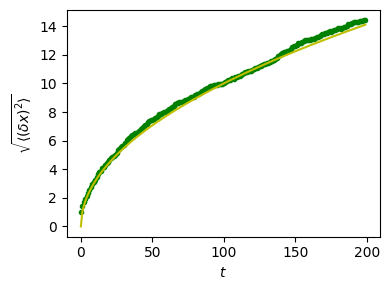

In [157]:
plt.figure(figsize=(4, 3))
plt.plot(t, np.sqrt(dist_carree_moy), 'g.', t, np.sqrt(t), 'y-')
plt.xlabel(r"$t$")
plt.ylabel(r"$\sqrt{\langle (\delta x)^2 \rangle}$")
plt.tight_layout() # laisse assez de place pour les légendes
plt.show()

Nous retrouvons un résultat bien connu en physique : la distance quadratique moyenne (RMS) croît comme la **racine carrée du temps**.

## Récapitulatif intermédiaire

| Type d'opération | Fonctions NumPy              |
| ---------------- | ---------------------------- |
| arithmétique     | `sum`, `prod`, `mean`, `std` |
| extrema          | `min`, `max`                 |
| logique          | `all`, `any`                 |

Rappelez-vous aussi l'argument `axis` pour choisir la dimension sur laquelle appliquer l'opération :

In [158]:
arr = np.array([[99, 12], [11, 2]])
arr

array([[99, 12],
       [11,  2]])

In [159]:
# Sans axis=, l'opération s'applique à tout le tableau (aplati, 1D).
np.min(arr)

np.int64(2)

In [160]:
# Opération le long du premier axe (lignes).
np.min(arr, axis=0)

array([11,  2])

In [161]:
# Opération le long du second axe (colonnes).
np.min(arr, axis=1)

array([12,  2])

> **Exercice : lire des données d'un fichier**
>
>
> NumPy lit et écrit facilement des fichiers texte avec `np.savetxt` et `np.loadtxt`. Créons d'abord un petit fichier de mesures :
>

In [162]:
rng = np.random.default_rng(0)
mesures = rng.normal(loc=5.0, scale=0.3, size=(5, 4))
np.savetxt('un_tableau.txt', mesures)

Rechargeons-le :

In [163]:
un_tableau = np.loadtxt('un_tableau.txt')
un_tableau

array([[5.03771907, 4.96036854, 5.1921268 , 5.03147004],
       [4.83929919, 5.10847852, 5.39120001, 5.28412429],
       [4.78887943, 4.62037356, 4.81301766, 5.01239779],
       [4.30249077, 4.9343625 , 4.62622672, 4.78031979],
       [4.83672231, 4.90510995, 5.12348916, 5.31275401]])

1. Vérifiez si tous les éléments de `un_tableau` sont égaux à 1.
2. Vérifiez si au moins un élément est égal à 1.
3. Calculez la moyenne et l'écart-type.
4. Défi : écrivez une fonction `mon_std` qui calcule l'écart-type des éléments du tableau, en n'utilisant de NumPy que `np.sum`. Vérifiez que votre fonction donne une valeur proche de `np.std` (utilisez `np.allclose`).

In [164]:
np.all(un_tableau == 1)
# Retourne False

np.False_

In [165]:
np.any(un_tableau == 1)
# Retourne False

np.False_

In [166]:
moyenne = np.mean(un_tableau)
ecart_type = np.std(un_tableau)

print("Moyenne :", moyenne)
print("Écart-type :", ecart_type)

Moyenne : 4.9450465047713825
Écart-type : 0.25526270692928


In [168]:
def mon_std(tab):
    N = tab.size
    # Calcul de la moyenne avec np.sum
    moy = np.sum(tab) / N
    # Calcul de l'écart-type avec np.sum
    variance = np.sum((tab - moy)**2) / N
    return variance**0.5

# Vérification de la fonction avec np.allclose
print(np.allclose(mon_std(un_tableau), np.std(un_tableau)))
# Retourne True

True


In [169]:
#@title Solution { display-mode: "form" }
# 1. Tous les éléments sont-ils égaux à 1 ?
print(np.all(un_tableau == 1))

# 2. Au moins un élément est-il égal à 1 ?
print(np.any(un_tableau == 1))

# 3. Moyenne et écart-type.
print('Moyenne', np.mean(un_tableau))
print('Écart-type', np.std(un_tableau))

# 4. Défi
def mon_std(a):
    n = a.size
    m = np.sum(a) / n
    return np.sqrt(np.sum((a - m) ** 2) / n)

assert np.allclose(mon_std(un_tableau), np.std(un_tableau))
assert np.allclose(mon_std(un_tableau.ravel()), np.std(un_tableau))
print("Vérifications réussies")

False
False
Moyenne 4.9450465047713825
Écart-type 0.25526270692928
Vérifications réussies


> 💡 **Astuce**
>
> **Avec Google Drive** : pour charger un fichier de données placé dans votre Drive, montez-le avec `from google.colab import drive; drive.mount('/content/drive')`, puis lisez-le avec par exemple `np.loadtxt('/content/drive/MyDrive/mes_donnees/mesures.txt')`.

## Broadcasting (diffusion)

- Les opérations de base sur les tableaux `numpy` (addition, etc.) se font élément par élément.
- Cela fonctionne sur des tableaux de même taille.
- **Néanmoins**, il est aussi possible d'opérer sur des tableaux de tailles différentes si *NumPy* peut les transformer pour qu'ils aient tous la même taille : cette conversion s'appelle le **broadcasting**.

L'image ci-dessous donne un exemple de broadcasting :

![Broadcasting](https://raw.githubusercontent.com/scipy-lectures/scipy-lecture-notes/master/intro/numpy/images/numpy_broadcasting.png)

Vérifions :

In [170]:
a = np.tile(np.arange(0, 40, 10), (3, 1)).T
a

array([[ 0,  0,  0],
       [10, 10, 10],
       [20, 20, 20],
       [30, 30, 30]])

In [171]:
b = np.array([0, 1, 2])
a + b

array([[ 0,  1,  2],
       [10, 11, 12],
       [20, 21, 22],
       [30, 31, 32]])

Nous avons déjà utilisé le broadcasting sans le savoir !

In [172]:
a = np.ones((4, 5))
a[0] = 2  # on affecte un tableau de dimension 0 à un tableau de dimension 1
a

array([[2., 2., 2., 2., 2.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.]])

Une astuce utile :

In [173]:
a = np.arange(0, 40, 10)
a.shape

(4,)

In [174]:
a = a[:, np.newaxis]  # ajoute un nouvel axe -> tableau 2D
a.shape

(4, 1)

In [175]:
a

array([[ 0],
       [10],
       [20],
       [30]])

In [176]:
a + b

array([[ 0,  1,  2],
       [10, 11, 12],
       [20, 21, 22],
       [30, 31, 32]])

Le broadcasting semble un peu magique, mais il est en fait très naturel à utiliser quand on veut résoudre un problème dont les données de sortie forment un tableau avec plus de dimensions que les données d'entrée.

### Exemple détaillé : le broadcasting

Construisons un tableau des distances (en miles) entre des villes de la Route 66 : Chicago, Springfield, Saint-Louis, Tulsa, Oklahoma City, Amarillo, Santa Fe, Albuquerque, Flagstaff et Los Angeles.

In [177]:
bornes = np.array([0, 198, 303, 736, 871, 1175, 1475, 1544,
       1913, 2448])
distances = np.abs(bornes - bornes[:, np.newaxis])
distances

array([[   0,  198,  303,  736,  871, 1175, 1475, 1544, 1913, 2448],
       [ 198,    0,  105,  538,  673,  977, 1277, 1346, 1715, 2250],
       [ 303,  105,    0,  433,  568,  872, 1172, 1241, 1610, 2145],
       [ 736,  538,  433,    0,  135,  439,  739,  808, 1177, 1712],
       [ 871,  673,  568,  135,    0,  304,  604,  673, 1042, 1577],
       [1175,  977,  872,  439,  304,    0,  300,  369,  738, 1273],
       [1475, 1277, 1172,  739,  604,  300,    0,   69,  438,  973],
       [1544, 1346, 1241,  808,  673,  369,   69,    0,  369,  904],
       [1913, 1715, 1610, 1177, 1042,  738,  438,  369,    0,  535],
       [2448, 2250, 2145, 1712, 1577, 1273,  973,  904,  535,    0]])

De nombreux problèmes sur grille ou sur réseau peuvent aussi utiliser le broadcasting. Par exemple, pour calculer la distance à l'origine des points d'une grille 5x5 :

In [178]:
x, y = np.arange(5), np.arange(5)[:, np.newaxis]
distance = np.sqrt(x ** 2 + y ** 2)
distance

array([[0.        , 1.        , 2.        , 3.        , 4.        ],
       [1.        , 1.41421356, 2.23606798, 3.16227766, 4.12310563],
       [2.        , 2.23606798, 2.82842712, 3.60555128, 4.47213595],
       [3.        , 3.16227766, 3.60555128, 4.24264069, 5.        ],
       [4.        , 4.12310563, 4.47213595, 5.        , 5.65685425]])

Ou en couleurs :

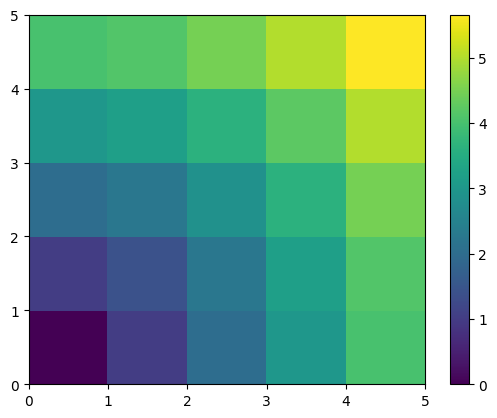

In [181]:
plt.pcolor(distance)
plt.colorbar()
plt.show()

**Remarque** : la fonction `np.ogrid` permet de créer directement les vecteurs x et y de l'exemple précédent, avec deux « dimensions significatives » :

In [179]:
x, y = np.ogrid[0:5, 0:5]
x, y

(array([[0],
        [1],
        [2],
        [3],
        [4]]),
 array([[0, 1, 2, 3, 4]]))

In [180]:
x.shape, y.shape
distance = np.sqrt(x ** 2 + y ** 2)

`np.ogrid` est donc très utile dès qu'on manipule des calculs sur une grille. De son côté, `np.mgrid` fournit directement des matrices pleines d'indices, pour les cas où l'on ne peut pas (ou ne veut pas) profiter du broadcasting :

In [182]:
x, y = np.mgrid[0:4, 0:4]
x

array([[0, 0, 0, 0],
       [1, 1, 1, 1],
       [2, 2, 2, 2],
       [3, 3, 3, 3]])

In [183]:
y

array([[0, 1, 2, 3],
       [0, 1, 2, 3],
       [0, 1, 2, 3],
       [0, 1, 2, 3]])

> **Exemple physique : le champ d'une charge ponctuelle sur une grille**
>
> Le potentiel électrostatique d'une charge $q$ placée à l'origine est $V = \dfrac{q}{4\pi\varepsilon_0 r}$. Grâce au broadcasting, on le calcule sur toute une grille en une seule expression :

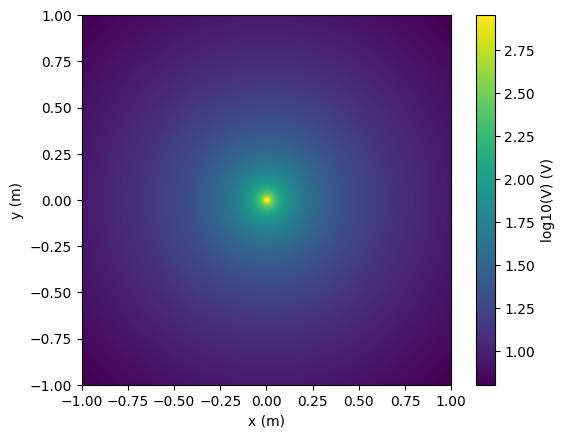

In [184]:
epsilon0 = 8.854e-12   # F/m
q = 1e-9               # 1 nC

x = np.linspace(-1, 1, 201)               # en mètres
y = np.linspace(-1, 1, 201)[:, np.newaxis]
r = np.sqrt(x**2 + y**2)
r[r < 0.01] = 0.01                        # évite la division par zéro à l'origine
V = q / (4 * np.pi * epsilon0 * r)

plt.imshow(np.log10(V), extent=[-1, 1, -1, 1], origin='lower')
plt.colorbar(label="log10(V) (V)")
plt.xlabel("x (m)"); plt.ylabel("y (m)")
plt.show()

## Manipulation de la forme des tableaux

### Aplatir

In [185]:
a = np.array([[1, 2, 3], [4, 5, 6]])
a.ravel()

array([1, 2, 3, 4, 5, 6])

In [186]:
a.T

array([[1, 4],
       [2, 5],
       [3, 6]])

In [187]:
a.T.ravel()

array([1, 4, 2, 5, 3, 6])

En dimensions supérieures, les dernières dimensions sont aplaties « en premier ».

### Changer la forme (*reshape*)

L'opération inverse de l'aplatissement :

In [188]:
a.shape

(2, 3)

In [189]:
b = a.ravel()
b = b.reshape((2, 3))
b

array([[1, 2, 3],
       [4, 5, 6]])

Ou bien :

In [190]:
a.reshape((2, -1))    # la valeur non précisée (-1) est déduite

array([[1, 2, 3],
       [4, 5, 6]])

> ⚠️ **Attention**
>
> `ndarray.reshape` **peut** renvoyer une vue (voir `help(np.reshape)`), ou une copie.


Par exemple :

In [191]:
b[0, 0] = 99
a

array([[99,  2,  3],
       [ 4,  5,  6]])

Attention, `reshape` peut aussi renvoyer une copie :

In [192]:
a = np.zeros((3, 2))
b = a.T.reshape(3*2)
b[0] = 9
a

array([[0., 0.],
       [0., 0.],
       [0., 0.]])

Pour comprendre cela, il faut en savoir plus sur l'organisation en mémoire d'un tableau NumPy.

### Ajouter une dimension

L'indexation avec l'objet `np.newaxis` permet d'ajouter un axe à un tableau (vous l'avez déjà vu plus haut, dans la section sur le broadcasting) :

In [193]:
z = np.array([1, 2, 3])
z

array([1, 2, 3])

In [194]:
z[:, np.newaxis]

array([[1],
       [2],
       [3]])

In [195]:
z[np.newaxis, :]

array([[1, 2, 3]])

### Permuter les dimensions

In [196]:
a = np.arange(4*3*2).reshape(4, 3, 2)
a.shape

(4, 3, 2)

In [197]:
a[0, 2, 1]

np.int64(5)

In [198]:
b = a.transpose(1, 2, 0)
b.shape

(3, 2, 4)

In [199]:
b[2, 1, 0]

np.int64(5)

Cela crée aussi une vue :

In [200]:
b[2, 1, 0] = -1
a[0, 2, 1]

np.int64(-1)

### Redimensionner

La taille d'un tableau peut être changée avec `ndarray.resize` :

In [201]:
a = np.arange(4)
a.resize((8,), refcheck=False)
a

array([0, 1, 2, 3, 0, 0, 0, 0])

Cependant, par défaut (`refcheck=True`), le tableau ne doit pas être référencé ailleurs :

In [202]:
# Erreur volontaire : un autre nom (b) désigne le même tableau
b = a
a.resize((4,))

ValueError: cannot resize an array that references or is referenced
by another object in this way.
Use the np.resize function to get a new resized copy or
 set refcheck=False to disable this check

> **Exercice**
>
> - Regardez la docstring de `reshape`, en particulier la section *Notes*, qui donne plus d'informations sur les copies et les vues.
> - Utilisez `flatten` comme alternative à `ravel`. Quelle est la différence ? (Indice : regardez lequel renvoie une vue et lequel une copie.)
> - Expérimentez avec `transpose` pour permuter les dimensions.

In [203]:
import numpy as np

# 1. Consulter la docstring de reshape
# help(np.reshape)

# 2. Démonstration : flatten vs ravel
arr = np.array([[1, 2], [3, 4]])

r = arr.ravel()   # Vue
f = arr.flatten() # Copie

r[0] = 99
print("Après modification de r[0] = 99 :")
print("Tableau original arr :\n", arr)  # arr[0, 0] est devenu 99 !

f[1] = 88
print("\nAprès modification de f[1] = 88 :")
print("Tableau original arr :\n", arr)  # arr reste inchangé

# 3. Expérimentation avec transpose
matrix = np.array([[1, 2, 3],
                   [4, 5, 6]])

transposed = matrix.transpose() # ou matrix.T
print("\nMatrice originale (2x3) :\n", matrix)
print("\nMatrice transposée (3x2) :\n", transposed)

Après modification de r[0] = 99 :
Tableau original arr :
 [[99  2]
 [ 3  4]]

Après modification de f[1] = 88 :
Tableau original arr :
 [[99  2]
 [ 3  4]]

Matrice originale (2x3) :
 [[1 2 3]
 [4 5 6]]

Matrice transposée (3x2) :
 [[1 4]
 [2 5]
 [3 6]]


**Réponses aux questions :**

* **`reshape` (vue vs copie) :** `reshape` essaie de renvoyer une vue (*view*) sans dupliquer les données en mémoire. Une copie n'est créée que si les données ne sont pas contiguës en mémoire.
* **`ravel` vs `flatten` :**
  * `ravel()` renvoie une vue (*view*) du tableau. Modifier le tableau aplati modifie aussi le tableau d'origine.
  * `flatten()` renvoie une copie (*copy*) indépendante. Les modifications n'impactent pas le tableau d'origine.
* **Expérimentation avec `transpose` :** La méthode `transpose()` (ou l'attribut `.T`) permet de permuter les dimensions d'un tableau :
  * Pour une matrice 2D de taille $(m, n)$, `transpose()` inverse les lignes et les colonnes pour donner une matrice de taille $(n, m)$.
  * Pour un tableau à plus de 2 dimensions (ex: 3D), on peut passer un tuple d'indices à `transpose()` (par exemple `transpose((1, 0, 2))`) pour spécifier exactement l'ordre dans lequel on souhaite réorganiser les axes.

## Trier des données

Tri le long d'un axe :

In [204]:
a = np.array([[4, 3, 5], [1, 2, 1]])
b = np.sort(a, axis=1)
b

array([[3, 4, 5],
       [1, 1, 2]])

Chaque ligne est triée séparément !

Tri sur place :

In [205]:
a.sort(axis=1)
a

array([[3, 4, 5],
       [1, 1, 2]])

Tri avec l'indexation avancée :

In [206]:
a = np.array([4, 3, 1, 2])
j = np.argsort(a)
j

array([2, 3, 1, 0])

In [207]:
a[j]

array([1, 2, 3, 4])

Trouver les minima et maxima :

In [208]:
a = np.array([4, 3, 1, 2])
j_max = np.argmax(a)
j_min = np.argmin(a)
j_max, j_min

(np.int64(0), np.int64(2))

**En résumé :**

- l'arithmétique, etc. se fait élément par élément ;
- algèbre linéaire de base : `@` ;
- réductions : `sum(axis=1)`, `std()`, `all()`, `any()` ;
- broadcasting : `a = np.arange(4); a[:,np.newaxis] + a[np.newaxis,:]` ;
- manipulation de forme : `a.ravel()`, `a.reshape(2, 2)` ;
- indexation avancée : `a[a > 3]`, `a[[2, 3]]` ;
- tri : `.sort()`, `np.sort`, `np.argsort`, `np.argmax`.


> **Exercice**
>
> - Essayez le tri sur place et le tri avec copie.
> - Créez des tableaux de différents types et triez-les.
> - Utilisez `all` ou `array_equal` pour vérifier les résultats.
> - Regardez `np.random.shuffle` pour créer plus vite des données à trier.
> - Combinez `ravel`, `sort` et `reshape`.
> - Regardez le mot-clé `axis` de `sort` et réécrivez l'exercice précédent avec.

In [212]:
import numpy as np

# 1. Tri sur place (.sort()) vs Tri avec copie (np.sort())
a = np.array([3, 1, 4, 2])
b = np.sort(a)     # Tri avec copie (a reste inchangé)
print("Tri avec copie np.sort(a) -> b:", b)
print("a d'origine intact :", a)

a.sort()           # Tri sur place (modifie a directement)
print("Tri sur place a.sort() -> a:", a)

# 2. Tableaux de différents types (float, string) et tri
arr_float = np.array([3.5, 1.2, 2.8], dtype=float)
arr_str = np.array(['orange', 'pomme', 'banane'], dtype=str)
print("\nTri de floats :", np.sort(arr_float))
print("Tri de chaînes :", np.sort(arr_str))

# 3. Vérification des résultats avec np.all ou np.array_equal
m1 = np.array([1, 2, 3])
m2 = np.array([1, 2, 3])
print("\nVérification avec np.all :", np.all(m1 == m2))
print("Vérification avec np.array_equal :", np.array_equal(m1, m2))

# 4. Utilisation de np.random.shuffle pour générer des données mélangées
data = np.arange(10)
np.random.shuffle(data)  # Mélange les éléments de data sur place
print("\nDonnées mélangées :", data)
print("Données triées après mélange :", np.sort(data))

# 5. Combinaison de ravel, sort et reshape
matrice = np.array([[4, 2], [1, 3]])
# Aplatir (ravel), trier, puis redimensionner (reshape)
matrice_triee = np.sort(matrice.ravel()).reshape(matrice.shape)
print("\nMatrice 2D d'origine :\n", matrice)
print("Matrice 2D entièrement triée (ravel + sort + reshape) :\n", matrice_triee)

# 6. Tri avec l'argument axis
# Tri le long des colonnes (axis=0) ou des lignes (axis=1)
print("\nTri par lignes (axis=1) :\n", np.sort(matrice, axis=1))
print("Tri par colonnes (axis=0) :\n", np.sort(matrice, axis=0))


Tri avec copie np.sort(a) -> b: [1 2 3 4]
a d'origine intact : [3 1 4 2]
Tri sur place a.sort() -> a: [1 2 3 4]

Tri de floats : [1.2 2.8 3.5]
Tri de chaînes : ['banane' 'orange' 'pomme']

Vérification avec np.all : True
Vérification avec np.array_equal : True

Données mélangées : [9 2 0 6 8 5 3 7 1 4]
Données triées après mélange : [0 1 2 3 4 5 6 7 8 9]

Matrice 2D d'origine :
 [[4 2]
 [1 3]]
Matrice 2D entièrement triée (ravel + sort + reshape) :
 [[1 2]
 [3 4]]

Tri par lignes (axis=1) :
 [[2 4]
 [1 3]]
Tri par colonnes (axis=0) :
 [[1 2]
 [4 3]]


## Bilan : que faut-il savoir pour démarrer ?

- Savoir créer des tableaux : `array`, `arange`, `ones`, `zeros`.
- Connaître la forme d'un tableau avec `array.shape`, puis utiliser le découpage pour obtenir différentes vues : `array[::2]`, etc. Ajuster la forme avec `reshape` ou l'aplatir avec `ravel`.
- Obtenir un sous-ensemble d'éléments et/ou modifier leurs valeurs avec des masques, par exemple :

  ```python
  a[a < 0] = 0
  ```

- Connaître les opérations diverses sur les tableaux, comme la moyenne ou le maximum (`array.max()`, `array.mean()`). Inutile de tout retenir, mais ayez le réflexe de chercher dans la documentation (docs en ligne, `help()`) !
- Pour un usage avancé : maîtriser l'indexation avec des tableaux d'entiers, ainsi que le broadcasting. Connaître plus de fonctions NumPy pour gérer diverses opérations sur les tableaux.

# Exercices de synthèse


> **Exercice : trajectoire d'un projectile**
>
> Un projectile est lancé depuis le sol avec une vitesse $v_0 = 20\ \text{m/s}$ et un angle de $45^\circ$. Sans frottements :
>
> $$x(t) = v_0 \cos\theta\, t, \qquad y(t) = v_0 \sin\theta\, t - \tfrac12 g t^2$$
>
> 1. Créez un tableau `t` de 200 instants entre 0 et la durée totale du vol $T = 2 v_0 \sin\theta / g$.
> 2. Calculez `x` et `y` sans boucle.
> 3. Trouvez la hauteur maximale et la portée avec `max()` et `argmax()`.
> 4. Tracez la trajectoire `y(x)`.

Hauteur maximale : 10.19 m
Portée du tir    : 40.77 m


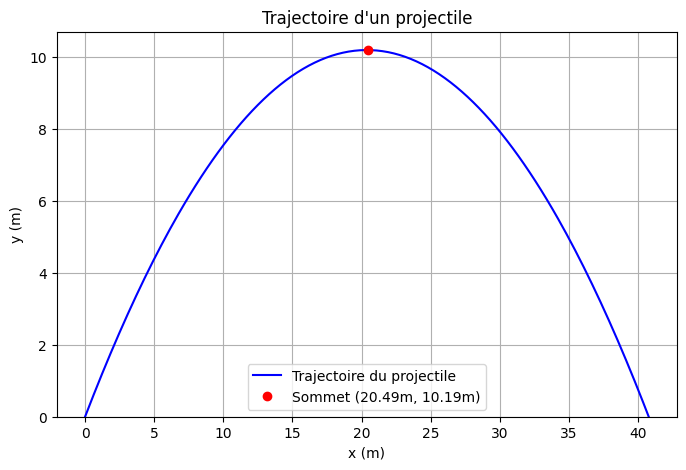

In [214]:
import numpy as np
import matplotlib.pyplot as plt

# Données du problème
v0 = 20.0             # Vitesse initiale en m/s
theta_deg = 45.0      # Angle en degrés
theta = np.radians(theta_deg) # Conversion de l'angle en radians
g = 9.81              # Accélération de la pesanteur en m/s²

# 1. Calcul du temps de vol total T et création du tableau t (200 points)
T = 2 * v0 * np.sin(theta) / g
t = np.linspace(0, T, 200)

# 2. Calcul des coordonnées x et y sans boucle
x = v0 * np.cos(theta) * t
y = v0 * np.sin(theta) * t - 0.5 * g * t**2

# 3. Hauteur maximale et portée avec max() et argmax()
hauteur_max = y.max()
portee = x.max()

idx_sommet = y.argmax()
x_sommet = x[idx_sommet]

print(f"Hauteur maximale : {hauteur_max:.2f} m")
print(f"Portée du tir    : {portee:.2f} m")

# 4. Tracé de la trajectoire y(x)
plt.figure(figsize=(8, 5))
plt.plot(x, y, label='Trajectoire du projectile', color='blue')
plt.plot(x_sommet, hauteur_max, 'ro', label=f'Sommet ({x_sommet:.2f}m, {hauteur_max:.2f}m)')

plt.title("Trajectoire d'un projectile")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.grid(True)
plt.legend()
plt.ylim(bottom=0)
plt.show()

Hauteur max : 10.19 m (à t = 1.45 s)
Portée      : 40.77 m


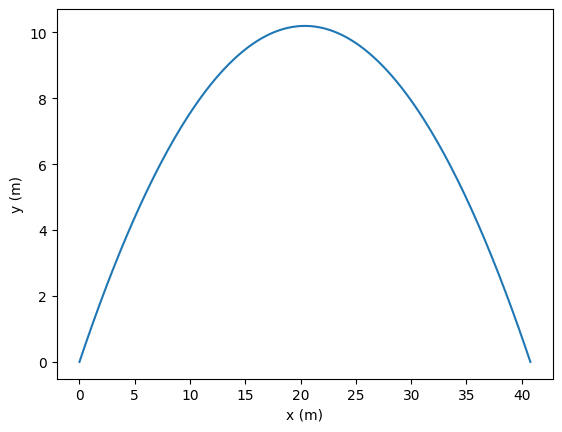

In [215]:
#@title Solution { display-mode: "form" }
g, v0, theta = 9.81, 20.0, np.radians(45)
T = 2 * v0 * np.sin(theta) / g
t = np.linspace(0, T, 200)
x = v0 * np.cos(theta) * t
y = v0 * np.sin(theta) * t - 0.5 * g * t**2

print(f"Hauteur max : {y.max():.2f} m (à t = {t[y.argmax()]:.2f} s)")
print(f"Portée      : {x[-1]:.2f} m")

plt.plot(x, y)
plt.xlabel("x (m)"); plt.ylabel("y (m)")
plt.show()

> **Exercice : Mesures et statistiques**
>
> On mesure 10 fois la période d'un pendule : `T = [2.01, 1.98, 2.03, 2.00, 1.99, 2.02, 2.05, 1.97, 2.00, 2.01]` (en s).
>
> 1. Calculez la moyenne et l'écart-type (avec `ddof=1` pour l'écart-type expérimental).
> 2. Calculez l'incertitude-type sur la moyenne, $u = s/\sqrt{N}$.
> 3. Déduisez la valeur de $g = 4\pi^2 L / T^2$ pour $L = 1{,}00\ \text{m}$.

In [216]:
import numpy as np

# Données expérimentales
T_mesures = np.array([2.01, 1.98, 2.03, 2.00, 1.99, 2.02, 2.05, 1.97, 2.00, 2.01])
L = 1.00  # Longueur en mètres

# 1. Moyenne et écart-type expérimental (ddof=1)
T_moy = np.mean(T_mesures)
s = np.std(T_mesures, ddof=1)

# 2. Incertitude-type sur la moyenne : u = s / sqrt(N)
N = len(T_mesures)
u = s / np.sqrt(N)

# 3. Déduction de la valeur de g = 4 * pi^2 * L / T^2
g = 4 * (np.pi**2) * L / (T_moy**2)

# Affichage des résultats
print(f"Moyenne de T (T_moy)           : {T_moy:.4f} s")
print(f"Écart-type expérimental (s)    : {s:.4f} s")
print(f"Incertitude-type (u)          : {u:.4f} s")
print(f"Accélération de la pesanteur g : {g:.4f} m/s²")

Moyenne de T (T_moy)           : 2.0060 s
Écart-type expérimental (s)    : 0.0237 s
Incertitude-type (u)          : 0.0075 s
Accélération de la pesanteur g : 9.8107 m/s²


In [217]:
#@title Solution { display-mode: "form" }
T = np.array([2.01, 1.98, 2.03, 2.00, 1.99, 2.02, 2.05, 1.97, 2.00, 2.01])
moy = T.mean()
s = T.std(ddof=1)
u = s / np.sqrt(T.size)
print(f"T = {moy:.3f} ± {u:.3f} s  (s = {s:.3f} s)")

L = 1.00
g = 4 * np.pi**2 * L / moy**2
print(f"g = {g:.2f} m/s²")

T = 2.006 ± 0.007 s  (s = 0.024 s)
g = 9.81 m/s²


---

*Fin du carnet 3. Suite : carnet 4 — Matplotlib.*